# Explainable Boosting Model Notebook

In our EDA, we compared mortgage denial rates across groups at three New York lenders. I was interested in whether a basic logistic model might miss patterns in the relationship between denial and the financial and neighborhood variables. For example, income might have a nonlinear relationship with the target variable, as it may only change in certain intervals or have a sudden shift in approval past a certain income.


**Please upload the file 'hdma_2025_ny_cleaned.csv" before running the notebook.**

## 1. Setup

We use InterpretML to fit the EBM and pandas and matplotlib to work with the data. We fix the InterpretML version so someone rerunning the notebook can use the same version.

In [1]:
%pip install -q interpret-core==0.7.8

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from importlib.metadata import version
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.metrics import confusion_matrix, classification_report

output_folder = Path("ebm_outputs")
output_folder.mkdir(exist_ok=True)
print("InterpretML:", version("interpret-core"))

InterpretML: 0.7.8


## 2. Load the cleaned data


In [3]:
hmda = pd.read_csv("hmda_2025_ny_cleaned.csv", dtype=str)

numeric_columns = ["income", "loan_amount", "tract_minority_population_percent"]
for column in numeric_columns + ["denied", "action_taken"]:
    hmda[column] = pd.to_numeric(hmda[column], errors="raise")

print("Applications:", len(hmda))
print("Denied:", hmda["denied"].sum())
print("Denial rate:", round(hmda["denied"].mean() * 100, 1), "%")
hmda.head()

Applications: 10513
Denied: 1476
Denial rate: 14.0 %


,activity_year,state_code,lei,action_taken,derived_race,derived_ethnicity,applicant_age,loan_type,debt_to_income_ratio,derived_msa-md,...,census_tract,income,loan_amount,tract_minority_population_percent,tract_to_msa_income_percentage,tract_population,denied,age_band,dti_band,tract_minority_band
0,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,35-44,1,30%-<36%,28740,...,36111952100,247.0,585000,52.21,68,3687,0,35-44,30%-<36%,40–<60%
1,2025,NY,7H6GLXDRUGQFU57RNE97,1,Joint,Not Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081026902,100.0,305000,95.74,61,4244,0,35-44,30%-<36%,80–100%
2,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,25-34,1,30%-<36%,35614,...,36119014701,125.0,225000,42.27,122,4977,0,25-34,30%-<36%,40–<60%
3,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Ethnicity Not Available,35-44,1,39,35614,...,36081092800,245.0,605000,9.14,181,3204,0,35-44,36%-49%,0–<20%
4,2025,NY,7H6GLXDRUGQFU57RNE97,2,White,Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081071304,100.0,85000,46.01,125,6386,0,35-44,30%-<36%,40–<60%


## 3. Choose predictors and split the sample

Race and ethnicity are included with respect to tract minority share to reflect that our study concerns the disparity among racial/ethnic groups and neighborhoods. Income, loan amount, debt-to-income (DTI), loan type, lender, and metro area provide the economic and institutional contexts for each application.

The target variable is action taken which represents whether a loan was approved or denied. Therefore, we do not include "action_taken" in this model. We also exclude all outcome dependent variables such as why an applicant was denied a loan.

DTI will be treated as categorical since it is impossible to assign a reasonable midpoint value to many of its ranges. All applicants were included regardless of how they may have been grouped together by specific EDA plots. However, we did retain all of the remaining applications and demographic categories that were omitted based on specific EDA plot requirements.

We randomly sampled 20% of the total number of applications into a test data set and used the remaining 80% of the data to create a training data set. To ensure that the proportion of denied applications would remain relatively consistent between the two datasets, we divided the sample equally by application status. To ensure that the same division could be reproduced at any time, we assigned a fixed random seed during sampling.

In [4]:
categorical_columns = ["derived_race", "derived_ethnicity", "dti_band", "loan_type", "lei", "derived_msa-md"]
features = numeric_columns + categorical_columns
X = hmda[features].copy()
y = hmda["denied"].astype(int)

# Preserve unavailable categories instead of dropping applications.
for column in categorical_columns:
    X[column] = X[column].fillna("Missing")

# Nonpositive income cannot be treated as ordinary positive annual income.
X["income_nonpositive"] = (X["income"] <= 0).astype(int)
X["income_unavailable"] = (X["income"].isna() | (X["income"] <= 0)).astype(int)
X.loc[X["income"] <= 0, "income"] = np.nan

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train = X_train.copy()
X_test = X_test.copy()

print("Training applications:", len(X_train))
print("Test applications:", len(X_test))
print("Unavailable/nonpositive income:", int(X["income_unavailable"].sum()))

Training applications: 8410
Test applications: 2103
Unavailable/nonpositive income: 469


## 4. Prepare missing values and fit the EBM

In total there were 395 missing incomes and 74 negative income values in the EDA data set; thus a total of 469. All of this data was retained and used in our analysis. In cases where an individual did not report their income, it will be replaced by the median income from our training data prior to analysis.

The loan amount and tract minority share features also presented no issues. These two features along with the income variable are kept in their original scale since the EBM model can create flexible relationship models (as opposed to being limited to log type transformations).

We initially analyze without interactions so that we can see how much each feature individually contributes to the overall prediction curves. For simplicity, we have chosen to utilize four out-of-bag samples per iteration and limit our boosting iterations to a max of 5000 iterations. As such, we are not utilizing the test set to determine parameters.

In [7]:
assert X_train[["loan_amount", "tract_minority_population_percent"]].notna().all().all()
assert X_test[["loan_amount", "tract_minority_population_percent"]].notna().all().all()
income_median = X_train["income"].median()
X_train["income"] = X_train["income"].fillna(income_median)
X_test["income"] = X_test["income"].fillna(income_median)

feature_types = ["continuous"] * 3 + ["nominal"] * 6 + ["nominal"] * 2

ebm = ExplainableBoostingClassifier(
    feature_types=feature_types,
    interactions=0,
    outer_bags=4,
    max_rounds=5000,
    n_jobs=2,
    random_state=42
)
ebm.fit(X_train, y_train)

ExplainableBoostingClassifier(feature_types=['continuous', 'continuous',
                                             'continuous', 'nominal', 'nominal',
                                             'nominal', 'nominal', 'nominal',
                                             'nominal', 'nominal', 'nominal'],
                              interactions=0, max_rounds=5000, n_jobs=2,
                              outer_bags=4)

## 5. Evaluate on held-out applications

We chose a few scores to evaluate the EBM. The ROC-AUC is used to assess whether the applications that were denied are ranked better than those that were approved. Larger values of the ROC-AUC represent better performance. Log loss and brier score are metrics which assess the performance of the probabilities (of approval) produced by the model. Lower values of log loss and brier score are better. To provide some context for evaluating these results, we simply assigned to each test application, the probability of being denied that existed during training. An always approve classifier would have been able to produce approximately 86% accuracy in this sample but, would not have identified a single denial.

In [8]:
probability = ebm.predict_proba(X_test)[:, 1]
predicted = (probability >= 0.5).astype(int)
baseline_probability = np.full(len(y_test), y_train.mean())

rows = []
for name, scores in [("Training-rate baseline", baseline_probability), ("EBM", probability)]:
    rows.append({
        "model": name,
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Log loss": log_loss(y_test, scores),
        "Brier score": brier_score_loss(y_test, scores)
    })
metrics = pd.DataFrame(rows).set_index("model")
display(metrics.round(4))

confusion = pd.DataFrame(
    confusion_matrix(y_test, predicted, labels=[0, 1]),
    index=["Actually approved", "Actually denied"],
    columns=["Predicted approved", "Predicted denied"]
)
display(confusion)
print(classification_report(
    y_test, predicted, labels=[0, 1],
    target_names=["Approved", "Denied"], zero_division=0
))

,ROC-AUC,Log loss,Brier score
model,,,
Training-rate baseline,0.5000,0.4055,0.1206
EBM,0.7909,0.2829,0.0765


,Predicted approved,Predicted denied
Actually approved,1798,10
Actually denied,175,120


              precision    recall  f1-score   support

    Approved       0.91      0.99      0.95      1808
      Denied       0.92      0.41      0.56       295

    accuracy                           0.91      2103
   macro avg       0.92      0.70      0.76      2103
weighted avg       0.91      0.91      0.90      2103



The false negatives are in the upper right cell in the confusion table/matrix. The false positives are in the lower left cell.

When we ran the EBM for the first time, the AUC-ROC of the EBM was 0.791. Compared to a probability of .5 always being used as the benchmark, the EBM lost less than the benchmark using 0.283 (log loss) versus 0.405; also, the Brier score of the EBM was less than the benchmark, 0.076 vs. 0.121. We were able to identify around 41% of true denials at an approval/denial cut point of 0.5 while still achieving an accuracy rate of approximately 91%. Given our results are based on only one split of the data, I do not think it is advisable to call the EBM "successful" on the basis of accuracy given how poorly the EBM performed at identifying true denials at this threshold.

## 6. Feature importance

Features that have an important influence are defined as those with the highest average absolute contribution across all of the training data (the average over all records) to fit the model's score. By using these values we will be able to compare the different features used by the model. Variables which are correlated may contain some common information, therefore the ordering established above does not imply causal relationships, nor is it based upon statistical measures of significance. Also, they do not necessarily represent what would be considered ethical issues to consider for the model.

Alt text: horizontal bars rank the features in descending order according to their mean absolute contribution to the fit in log odds units. A longer bar indicates that this particular feature has a greater contribution than another shorter bar for this specific model.

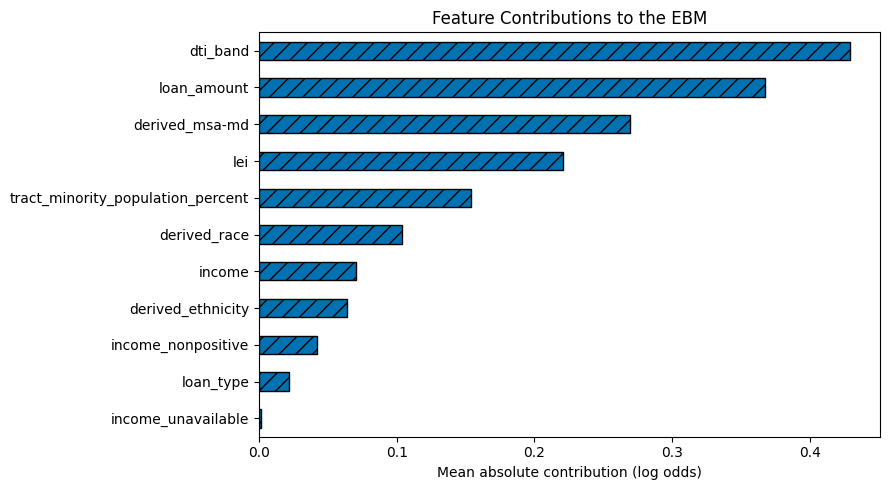

,feature,importance
5,dti_band,0.4295
1,loan_amount,0.3676
8,derived_msa-md,0.2696
7,lei,0.2208
2,tract_minority_population_percent,0.1536
3,derived_race,0.1036
0,income,0.0703
4,derived_ethnicity,0.0635
9,income_nonpositive,0.0420
6,loan_type,0.0220


In [10]:
importance = pd.DataFrame({
    "feature": ebm.term_names_,
    "importance": ebm.term_importances()
}).sort_values("importance")

ax = importance.plot.barh(
    x="feature", y="importance", legend=False, figsize=(9, 5),
    color="#0072B2", edgecolor="black", hatch="//"
)
ax.set_title("Feature Contributions to the EBM")
ax.set_xlabel("Mean absolute contribution (log odds)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(output_folder / "feature_importance.png", dpi=180)
plt.show()
display(importance.sort_values("importance", ascending=False).round(4))

## 7. Income and neighborhood relationships

After completing our EDA for this section, we assessed the correlations among all continuous predictors and how they relate to the variable "denial". Our EDA revealed that a decline in income had a decreasing trend and that denial was increasing as tract minority share increased toward the upper end. Now, we will investigate if the EBM has similar trends in correlation with the additional selected predictor(s).

We created a chart to see how much of a feature's contribution falls within its training-data 1st to 99th percentiles. Below the chart are histograms showing the location of actual applications. The charts were produced using the entire range of data points from the training set. A positive score indicates an increase in log odds of denial compared to the model's centering score. It does not represent a one-percentage point change in the probability of denial. We used a log income scale, just like we did in the EDA. Because we disabled interactions earlier, we are able to isolate the effects of each individual feature.

Alt Text: Four panes illustrate how EBM feature contributions exceed their respective training data distributions.
Income's contribution to estimated denial is generally in the mid-range, but it fluctuates as income levels rise, especially at the highest income levels (where there are fewer applications). A logarithmic scale for income is shown in thousand dollar increments. The contribution of the percent of a tract that is composed of minorities tends to increase as the percent minority share of a tract increases. The increase becomes steeper at about 80% minority.

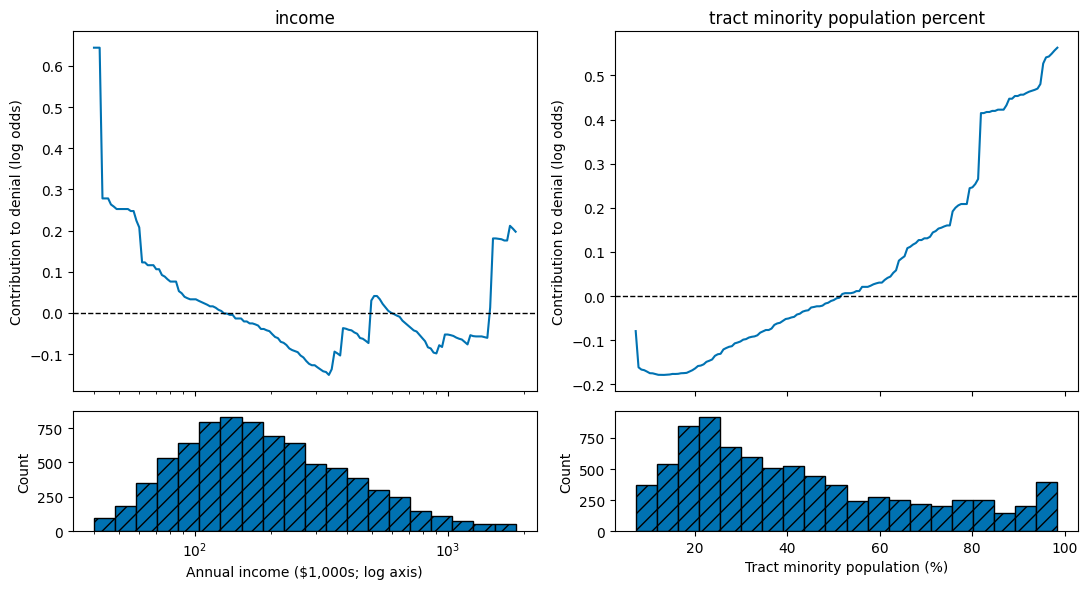

In [9]:
fig, axes = plt.subplots(
    2, 2, figsize=(11, 6), gridspec_kw={"height_ratios": [3, 1]},
    sharex="col"
)
plot_features = ["income", "tract_minority_population_percent"]
plot_labels = ["Annual income ($1,000s; log axis)", "Tract minority population (%)"]

for j, column in enumerate(plot_features):
    values = X_train[column]
    if column == "income":
        values = X_train.loc[X_train["income_unavailable"] == 0, column]
    low, high = values.quantile([0.01, 0.99])
    grid = np.geomspace(low, high, 150) if column == "income" else np.linspace(low, high, 150)

    plot_data = pd.concat([X_train.iloc[[0]]] * len(grid), ignore_index=True)
    plot_data[column] = grid
    term_index = list(X_train.columns).index(column)
    contributions = ebm.eval_terms(plot_data)[:, term_index]

    axes[0, j].plot(grid, contributions, color="#0072B2")
    axes[0, j].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[0, j].set_title(column.replace("_", " "))
    axes[0, j].set_ylabel("Contribution to denial (log odds)")
    bins = np.geomspace(low, high, 21) if column == "income" else np.linspace(low, high, 21)
    axes[1, j].hist(values, bins=bins, color="#0072B2", edgecolor="black", hatch="//")
    axes[1, j].set_xlabel(plot_labels[j])
    axes[1, j].set_ylabel("Count")
    if column == "income":
        axes[1, j].set_xscale("log")

plt.tight_layout()
plt.savefig(output_folder / "feature_shapes.png", dpi=180)
plt.show()

Income was the second largest contributor in the first iteration based upon averages across all observations, following DTI band and preceding Loan Amount, Metro Area and Lender. While income continued to decline as one moved up into the middle of its range, we see random fluctuation at the high end of the income scale instead of what we expected: a clear leveling off. Tract minority share also increased positively to the right.

## 8. Observed and predicted rates across groups

We compare the observed denial rate for each group with its mean predicted probability on the test applications.

In [13]:
test_results = hmda.loc[y_test.index, ["derived_race", "derived_ethnicity"]].copy()
test_results["denied"] = y_test
test_results["predicted_probability"] = probability
test_results["predicted_denied"] = predicted

for column in ["derived_race", "derived_ethnicity"]:
    group_table = test_results.groupby(column, dropna=False).agg(
        applications=("denied", "size"),
        denials=("denied", "sum"),
        observed_denial_rate=("denied", "mean"),
        mean_predicted_probability=("predicted_probability", "mean")
    )
    print(column)
    display(group_table.round(3))
    group_table.to_csv(output_folder / (column + "_test_summary.csv"))

derived_race


,applications,denials,observed_denial_rate,mean_predicted_probability
derived_race,,,,
2 or more minority races,3,0,0.000,0.281
American Indian or Alaska Native,6,1,0.167,0.155
Asian,461,69,0.150,0.159
Black or African American,162,39,0.241,0.252
Free Form Text Only,3,2,0.667,0.698
Joint,96,8,0.083,0.100
Native Hawaiian or Other Pacific Islander,5,0,0.000,0.171
Race Not Available,216,45,0.208,0.200
White,1151,131,0.114,0.119


derived_ethnicity


,applications,denials,observed_denial_rate,mean_predicted_probability
derived_ethnicity,,,,
Ethnicity Not Available,168,29,0.173,0.171
Free Form Text Only,3,1,0.333,0.403
Hispanic or Latino,183,33,0.180,0.230
Joint,55,5,0.091,0.090
Not Hispanic or Latino,1694,227,0.134,0.137


## Saving Results (run this one to automatically download all the stuff made in this notebook)

In [12]:
metrics.to_csv(output_folder / "test_metrics.csv")
confusion.to_csv(output_folder / "confusion_matrix.csv")
importance.to_csv(output_folder / "feature_importance.csv", index=False)
test_results.to_csv(output_folder / "test_predictions.csv", index_label="source_row")

import shutil
from google.colab import files

shutil.make_archive("ebm_results", "zip", output_folder)
files.download("ebm_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>